### Week 11 Examples: Pandas: ###

Joining DataFrames, Grouping


In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set the option to display all columns
pd.set_option('display.max_columns', None)
# Set the option to display more width (scroll to the right)
pd.set_option('display.width', 1000)



Joining DataFrames

In [ ]:
# load data files:
df_components = pd.read_csv("https://raw.githubusercontent.com/bu-cds-omds/dx602-examples/refs/heads/main/data/components.tsv", sep='\t')
df_orders = pd.read_csv("https://raw.githubusercontent.com/bu-cds-omds/dx602-examples/refs/heads/main/data/orders.tsv", sep='\t')

## examine the data in each DataFrame:
print("COMPONENTS")
print(df_components)
print("ORDERS")
print(df_orders)

# # join (merge) these two dataframes together
df_component_orders = df_components.merge(df_orders, on="device")
df_component_orders['order_qty'] = df_component_orders['component_quantity'] * df_component_orders['device_quantity']
print(df_component_orders)
# # what is total number of stuffs do we need to fulfill the orders?
print(df_component_orders.groupby('component')['order_qty'].sum())



Load Chicago Marathon Data

In [ ]:
# load data file:
df_marathon = pd.read_csv("https://raw.githubusercontent.com/bu-cds-omds/dx602-examples/refs/heads/main/data/2026_chicago_results.csv", index_col="BIB")



Exploratory data analysis:
- explore some columns/values
- use groups of columns together

bins =  442


Text(0, 0.5, 'count')

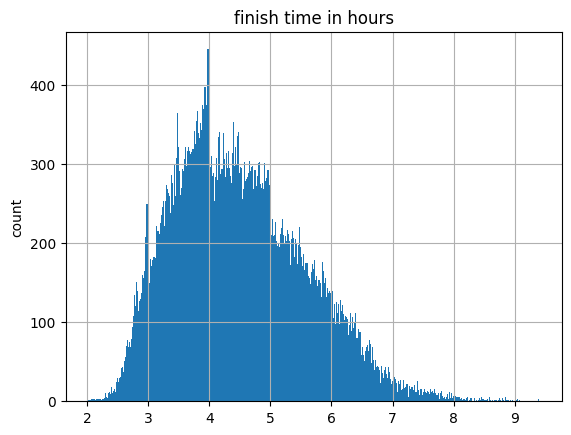

In [26]:
columns = ['name_(ctz)', 'gender', 'division', 'place_overall', 'finish']
time_columns = ['05k_hours', '10k_hours', '15k_hours', '20k_hours',
       'half_hours', '25k_hours', '30k_hours', 'mile_20_hours',
       'mile_21_hours', '35k_hours', 'mile_22_hours', 'mile_23_hours',
       'mile_24_hours', '40k_hours', 'mile_25_hours', 'mile_25.2_hours',
       'finish_hours', 'half_2_hours']
pace_columns = ['05k_pace', '10k_pace', '15k_pace',
       '20k_pace', '25k_pace', '30k_pace', '35k_pace', '40k_pace']

# print(df_marathon.columns) # show all columns as a "list" (pandas index)
# print(df_marathon[columns])
# print(df_marathon[time_columns[:5]]) # show first 5

# print(df_marathon['finish_hours'].describe()) # basic descriptive stats
num_bins = int(60 * (df_marathon['finish_hours'].max() - df_marathon['finish_hours'].min()))
print('bins = ', num_bins)
df_marathon['finish_hours'].hist(bins=num_bins)
plt.title("finish time in hours")
plt.ylabel("count")

Grouping data by gender

                 count      mean       std       min       25%       50%       75%       max
gender                                                                                      
Man            29378.0  4.240077  1.035676  2.019167  3.456111  4.069722  4.892986  9.398333
Non-binary       149.0  4.621734  1.255144  2.471111  3.648889  4.331944  5.596667  8.423056
Not specified     64.0  4.713915  1.080628  2.972500  3.890556  4.650139  5.460139  6.881389
Woman          24990.0  4.806500  1.057728  2.225833  3.983056  4.707500  5.515000  9.398611


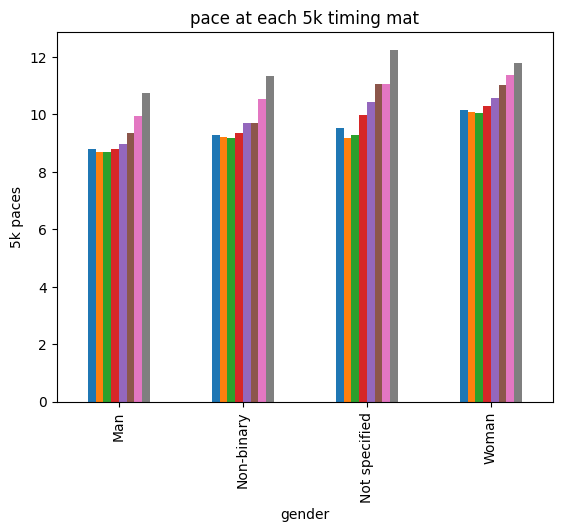

               05k_pace  10k_pace  15k_pace  20k_pace  25k_pace  30k_pace  35k_pace  40k_pace
gender                                                                                       
Man                 1.0  0.987783  0.985950  1.000000  1.020159  1.064753  1.128894  1.222053
Non-binary          1.0  0.993329  0.989559  1.008121  1.046404  1.046404  1.138631  1.222738
Not specified       1.0  0.963308  0.975445  1.046288  1.095682  1.159469  1.160034  1.286480
Woman               1.0  0.994171  0.992051  1.013249  1.042395  1.085321  1.122152  1.162692


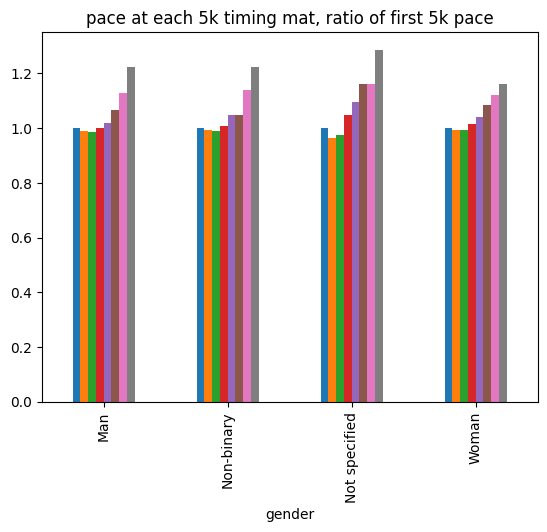

In [72]:
# print(df_marathon['finish_hours'].describe())
grouped = df_marathon.groupby('gender')
# 'grouped' is a DataFrameGroupByObject
# use aggregate method (min, max, count, mean, etc.) on a column
# print(grouped['finish_hours'].count())
print(grouped['finish_hours'].describe())

# finish times by group
# grouped['finish_hours'].median().plot(kind='bar')
# plt.ylabel('finish time in hours')
# plt.show()

# 5 pace times by group
grouped[pace_columns].median().plot(kind='bar', legend=False)
plt.ylabel('5k paces')
plt.title('pace at each 5k timing mat')
plt.show()

# calculate each pace as ratio of "starting" pace
# values are standardized to 1.0 starting pace, larger number means more slowing
# --> this shows how much women slow down compared to men
# print('grouped[pace_columns].median()')
# print(grouped[pace_columns].median())
# print("grouped['05k_pace'].median()")
# print(grouped['05k_pace'].median())
pace_ratio = grouped[pace_columns].median().div( grouped['05k_pace'].median(), axis=0) 
print(pace_ratio)
pace_ratio.plot(kind='bar', legend=False)
plt.title('pace at each 5k timing mat, ratio of first 5k pace')
plt.show()

Box plot of finish times by divisions

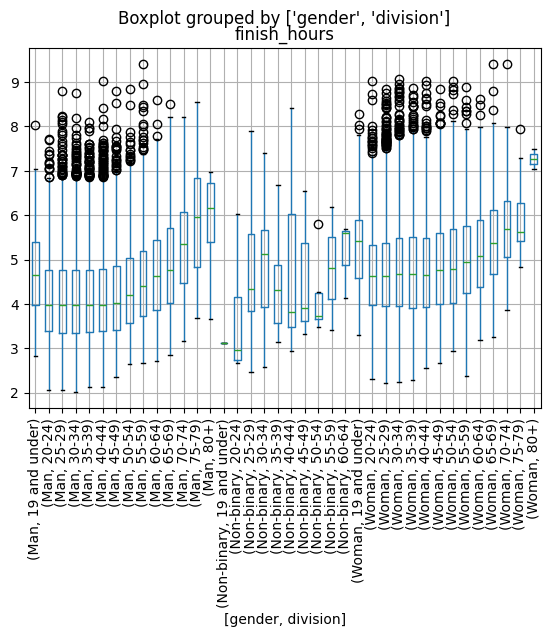

                          count      mean       std       min       25%       50%       75%       max
gender     division                                                                                  
Man        19 and under   143.0  4.685350  0.974422  2.826111  3.979444  4.659444  5.391667  8.041667
           20-24         1450.0  4.127262  1.022977  2.048889  3.379236  3.974306  4.769167  7.721667
           25-29         4481.0  4.118949  1.020944  2.062778  3.347222  3.985556  4.763611  8.809444
           30-34         4830.0  4.127672  1.010202  2.019167  3.346111  3.970833  4.762708  8.763056
           35-39         4549.0  4.136047  1.019357  2.126111  3.368333  3.964722  4.766667  8.112222
           40-44         4181.0  4.159952  0.996210  2.115278  3.393611  3.981667  4.778333  9.035278
           45-49         3419.0  4.214635  1.006276  2.342778  3.405278  4.019167  4.850694  8.804444
           50-54         2595.0  4.359868  0.985004  2.641667  3.574306  4.198611 

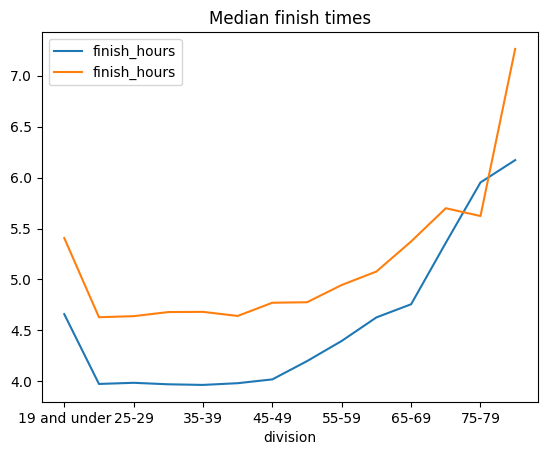

In [50]:
df_marathon.boxplot(column=['finish_hours'],
                    by=['gender', 'division'],
                    rot=90)
plt.show() # clear the buffer, show the chart

grouped_by_div = df_marathon.groupby(['gender', 'division'])
print(grouped_by_div['finish_hours'].describe())

# graph with average finish times for men/women
ax = grouped_by_div['finish_hours'].median().loc['Man'].plot(legend=True)
ax = grouped_by_div['finish_hours'].median().loc['Woman'].plot(legend=True)
plt.title('Median finish times')
plt.show() # clear the buffer, show the chart


Exploratory analysis: scatter plots


Text(0.5, 0, '05k_pace in minutes')

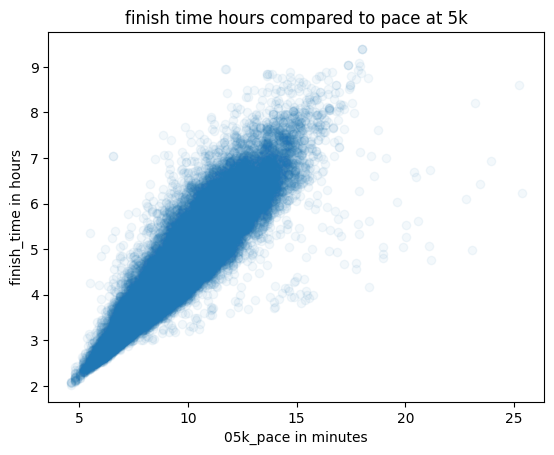

In [54]:
## basic plot of 2 columns
plt.scatter(df_marathon['05k_pace'], df_marathon['finish_hours'], alpha=0.05) # x series, y series
plt.title("finish time hours compared to pace at 5k")
plt.ylabel('finish_time in hours')
plt.xlabel('05k_pace in minutes')


Another example: with color by gender

Text(0.5, 0, '05k_pace in minutes')

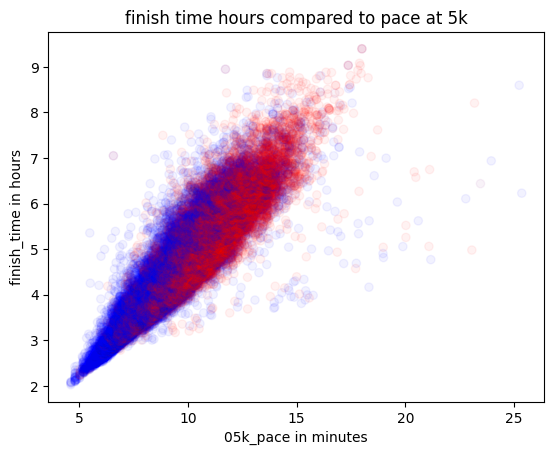

In [57]:
## add coloring by gender group
colors = {'Man':'blue', 'Woman': 'red', 'Non-binary': 'purple', 'Not specified':'black'}

# add a column to the data frame with color by gender
df_marathon['color'] = df_marathon['gender'].map(colors)
# print(df_marathon[['gender', 'color']].sample(25))
plt.scatter(df_marathon['05k_pace'], df_marathon['finish_hours'], 
            alpha=0.05, color=df_marathon['color'])
plt.title("finish time hours compared to pace at 5k")
plt.ylabel('finish_time in hours')
plt.xlabel('05k_pace in minutes')


Grouping data by gender, division

{'30-34': '#1f77b4', '20-24': '#ff7f0e', '25-29': '#2ca02c', '40-44': '#d62728', '35-39': '#9467bd', '45-49': '#8c564b', '50-54': '#e377c2', '55-59': '#7f7f7f', '60-64': '#bcbd22', '65-69': '#17becf'}


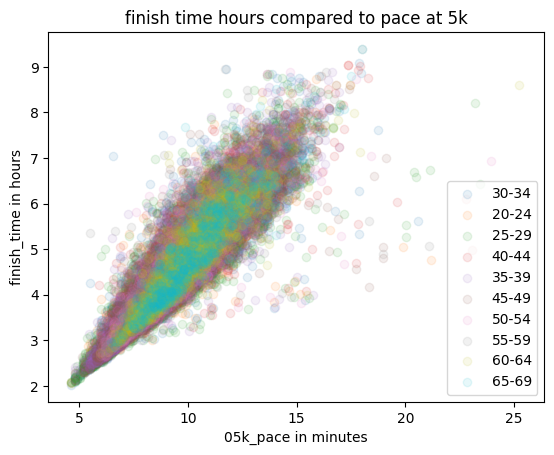

In [68]:
# go through each gender one at time:
unique_genders = df_marathon['gender'].unique()
# print(unique_genders)

# create color for each age division
colors = dict(zip(df_marathon['division'].unique(),
    plt.rcParams['axes.prop_cycle'].by_key()['color']))
print(colors)

# go through each division
for div in colors.keys():
    # query the whole data frame to obtain a subset for this age group
    df_div = df_marathon.query(f"division == '{div}'")
    # scatter plot per age group/division
    plt.scatter(df_div['05k_pace'], df_div['finish_hours'], alpha=0.1, color=colors[div])

plt.title("finish time hours compared to pace at 5k")
plt.ylabel('finish_time in hours')
plt.xlabel('05k_pace in minutes')
plt.legend(colors.keys())



Create nicely-formatted time, show table

In [ ]:
def format_hh_mm_ss(hours):
    '''Convert a value in hours to HH:MM:SS formatting.'''
    h = int(hours)
    m = (hours - h) * 60
    s = (m - int(m)) * 60
    m = int(m)
    s = int(s)
    
    return f"{h:02}:{m:02}:{s:02}"




Query by criteria